# Figure 02 · Target smoothing · kết quả tự train

15 dataset,4 model,4 hệ số,240ô/576fit. Tham số công bố chọn bằng validation; đủ original auto seeds.

Notebook này **đọc output thật đã audit rồi tính trung bình/vẽ lại**,không fit model hay chạy HPO.
Đây là accuracy thô của nhóm,không phải đường chuẩn hóa lấy từ paper.
Ba bộ numeric đại diện có thể kiểm tra offline ở `../results/numeric/`.
Xem notebook phân tích kết quả tác giả riêng tại `../../notebooks/`.

In [1]:
from pathlib import Path
import sys, json, io
from IPython.display import display, Image
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'reproduce/results/mechanism_cells.csv').exists())
sys.path.insert(0, str(ROOT / 'reproduce/scripts'))
from plots import cells, plot, means


In [2]:
frame = cells('target_smoothing')
assert len(frame) == 240
display(frame[['dataset','model','condition','required_seeds','test_accuracy_mean','validation_accuracy_mean']].head(12))

,dataset,model,condition,required_seeds,test_accuracy_mean,validation_accuracy_mean
12,credit,ft_transformer,"[0.0, ""robust""]","[0, 1]",0.736170,0.745035
13,MagicTelescope,ft_transformer,"[0.1, ""robust""]","[0, 1, 2]",0.848992,0.845664
14,electricity,ft_transformer,"[0.1, ""robust""]",[0],0.799167,0.795481
15,MagicTelescope,ft_transformer,"[0.25, ""robust""]","[0, 1, 2]",0.839265,0.840676
16,pol,ft_transformer,"[0.1, ""robust""]","[0, 1, 2]",0.904784,0.912165
17,pol,ft_transformer,"[0.25, ""robust""]","[0, 1, 2]",0.889991,0.899302
18,credit,ft_transformer,"[0.25, ""robust""]","[0, 1]",0.736809,0.739076
19,MagicTelescope,ft_transformer,"[0.0, ""robust""]","[0, 1, 2]",0.845789,0.842616
20,electricity,ft_transformer,"[0.0, ""robust""]",[0],0.804335,0.799227
21,pol,ft_transformer,"[0.0, ""robust""]","[0, 1, 2]",0.957979,0.959206


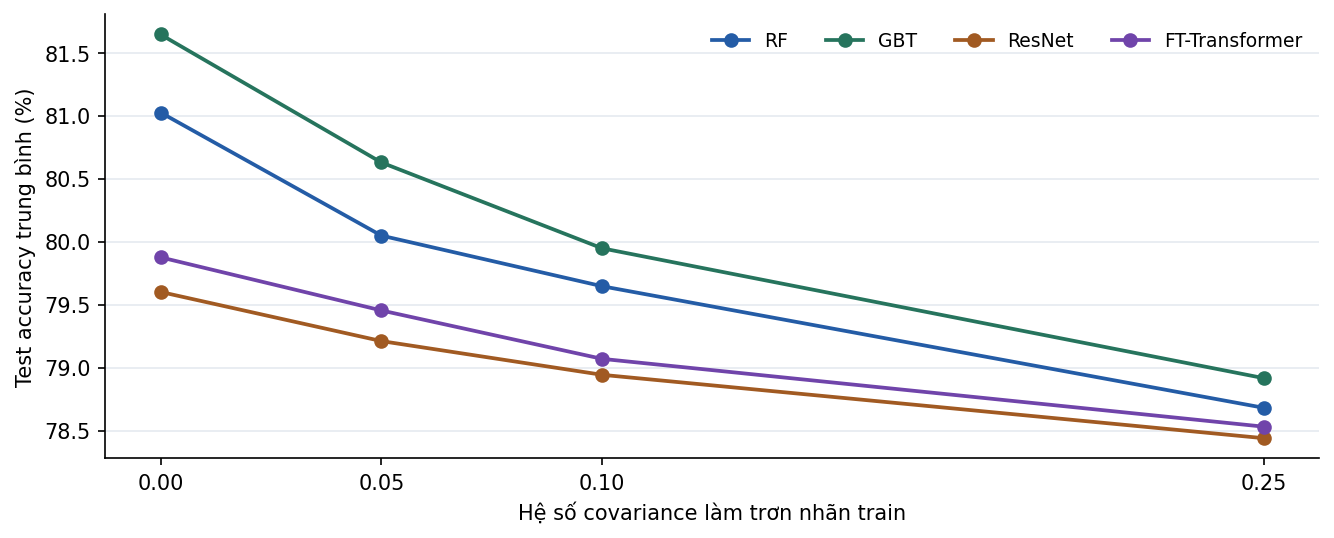

In [3]:
fig = plot('target_smoothing')
buf = io.BytesIO()
fig.savefig(buf, format='png', dpi=150, bbox_inches='tight')
display(Image(data=buf.getvalue()))

## Một fit gốc đại diện
Nhãn,dự đoán và rowID được lưu;số liệu dưới là một seed,không thay cho toàn bộ grid.

In [4]:
examples = json.loads((ROOT / 'reproduce/results/sample_fits.json').read_bytes())
example = next(e for e in examples if e['id'] == 'target_smoothing')
display({k: example[k] for k in ['dataset','model','seed','condition','metrics','source_record']})

{'dataset': 'electricity',
 'model': 'rf',
 'seed': 0,
 'condition': [0.1, 'robust'],
 'metrics': {'train': {'accuracy': 0.9999,
   'confusion_matrix': [[5049, 0], [1, 4950]]},
  'validation': {'accuracy': 0.8097635214235542,
   'confusion_matrix': [[3464, 811], [814, 3453]]},
  'test': {'accuracy': 0.809351796106763,
   'confusion_matrix': [[8166, 1785], [2015, 7966]]}},
 'source_record': 57604}

## Nếu muốn train lại
Đọc `../training/README.md` rồi dùng lệnh thủ công với Python3.8. Run All của notebook này luôn chỉ phân tích dữ liệu đã lưu;không gửi job.